In [14]:
#importing necessary libraries

from nilearn import datasets
from nilearn.datasets import fetch_atlas_schaefer_2018
from nilearn import plotting
from nilearn.maskers import NiftiLabelsMasker
from nilearn.connectome import ConnectivityMeasure
from scipy.spatial.distance import cdist
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import glob
import networkx as nx
%matplotlib inline 

In [3]:
#Data Acquisition: The ABIDE dataset is used for this pilot project. 
abide = datasets.fetch_abide_pcp(pipeline='dparsf', derivatives=[])
df = pd.DataFrame(abide.phenotypic)
print(df.columns.tolist()) 
print()
print("Atypical Subjects:")
df_asd = df[(df['SEX'] == 2) & (df['AGE_AT_SCAN'] < 30) & (df['AGE_AT_SCAN'] > 18) & (df['DX_GROUP'] == 1) & (df['EYE_STATUS_AT_SCAN'] == 1) & (df['FIQ'] > 100)].head(2) 
print(df_asd)
print()
print("Typical Subjects:")
df_normal = df[(df['SEX'] == 2) & (df['AGE_AT_SCAN'] < 30) & (df['AGE_AT_SCAN'] > 18) & (df['DX_GROUP'] == 2) & (df['EYE_STATUS_AT_SCAN'] == 1) & (df['FIQ'] > 100)].head(2) 
print(df_normal) 
print()
id_list = df_asd['SUB_ID'].tolist() + df_normal['SUB_ID'].tolist() #Extracting the subject IDs of the selected subjects and combining them into a single list.
print(id_list)
print("Data Downloading:")
datasets.fetch_abide_pcp(pipeline='dparsf', SUB_ID=id_list, derivatives=['func_preproc']) #Downloading the preprocessed functional MRI data for the selected subjects using the specified pipeline and subject IDs. The downloaded data will be stored in the default location for the ABIDE dataset.

[fetch_abide_pcp] Dataset directory found: C:\Users\elifn\nilearn_data\ABIDE_pcp
['i', 'Unnamed: 0', 'SUB_ID', 'X', 'subject', 'SITE_ID', 'FILE_ID', 'DX_GROUP', 'DSM_IV_TR', 'AGE_AT_SCAN', 'SEX', 'HANDEDNESS_CATEGORY', 'HANDEDNESS_SCORES', 'FIQ', 'VIQ', 'PIQ', 'FIQ_TEST_TYPE', 'VIQ_TEST_TYPE', 'PIQ_TEST_TYPE', 'ADI_R_SOCIAL_TOTAL_A', 'ADI_R_VERBAL_TOTAL_BV', 'ADI_RRB_TOTAL_C', 'ADI_R_ONSET_TOTAL_D', 'ADI_R_RSRCH_RELIABLE', 'ADOS_MODULE', 'ADOS_TOTAL', 'ADOS_COMM', 'ADOS_SOCIAL', 'ADOS_STEREO_BEHAV', 'ADOS_RSRCH_RELIABLE', 'ADOS_GOTHAM_SOCAFFECT', 'ADOS_GOTHAM_RRB', 'ADOS_GOTHAM_TOTAL', 'ADOS_GOTHAM_SEVERITY', 'SRS_VERSION', 'SRS_RAW_TOTAL', 'SRS_AWARENESS', 'SRS_COGNITION', 'SRS_COMMUNICATION', 'SRS_MOTIVATION', 'SRS_MANNERISMS', 'SCQ_TOTAL', 'AQ_TOTAL', 'COMORBIDITY', 'CURRENT_MED_STATUS', 'MEDICATION_NAME', 'OFF_STIMULANTS_AT_SCAN', 'VINELAND_RECEPTIVE_V_SCALED', 'VINELAND_EXPRESSIVE_V_SCALED', 'VINELAND_WRITTEN_V_SCALED', 'VINELAND_COMMUNICATION_STANDARD', 'VINELAND_PERSONAL_V_SCALE

{'description': ".. _abide_dataset:\n\nABIDE PCP dataset\n=================\n\nAccess\n------\nSee :func:`nilearn.datasets.fetch_abide_pcp`.\n\nNotes\n-----\nThe Autism Brain Imaging Data Exchange (ABIDE) dataset provides previously\ncollected resting state functional magnetic resonance imaging datasets\nfrom 539 individuals with ASD and 573 typical controls for the purpose\nof data sharing in the broader scientific community. This grass-root\ninitiative involved 16 international sites, sharing 20 samples yielding\n1112 datasets composed of both MRI data and an extensive array of\nphenotypic information common across nearly all sites (see below).\n\nNote that this is the preprocessed version of ABIDE provided by the\npreprocess connectome projects (PCP).\n\nSee :footcite:t:`Nielsen2013`.\n\nContent\n-------\n    :'phenotypic': Behavioral information.\n\nReferences\n----------\n\n.. footbibliography::\n\nFor more information about this dataset's structure:\n\nhttp://preprocessed-connect

In [7]:
#Finding the fMRI files in the specified directory
file_path = r"C:\Users\elifn\Desktop\asd\eq\new_s*_func_preproc.nii"
fmri_files = glob.glob(file_path) #glob means to find all the pathnames matching a specified pattern according to the rules used by the Unix shell, although results are returned in arbitrary order7.

In [8]:
#Download the Schaefer atlas with 100 parcels and 7 networks TR = 3 Voxel size = 3, and applying marker to extract time series from the fMRI data using the atlas labels. The time series are standardized, detrended, and filtered with a low-pass filter of 0.1 Hz and a high-pass filter of 0.01 Hz. The repetition time (TR) is set to 3 seconds, and verbose output is enabled for progress tracking.
atlas = fetch_atlas_schaefer_2018(n_rois=100, yeo_networks=7, resolution_mm=2) 
masker = NiftiLabelsMasker(labels_img=atlas.maps, 
                           standardize=True,  
                           detrend=True,      
                           low_pass=0.1,      
                           high_pass=0.01,    
                           t_r=3.0,           
                           verbose=1)

[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\elifn\nilearn_data\schaefer_2018


In [ ]:
#Next step is to extract time series from the fMRI data using the atlas labels
correlation_measure = ConnectivityMeasure(kind='partial correlation') # Partial correlation to reduce indirect functional associations mediated by other brain regions, aiming to better characterize direct long-range functional connectivity.
all_time_series = []
all_correlation_matrices = []

for fmri_file in fmri_files:
    time_series = masker.fit_transform(fmri_file) #Extracting the time series from the fMRI data using the masker object. The fit_transform method applies the masker to the fMRI file and returns the extracted time series.
    all_time_series.append(time_series) #Appending the extracted time series to the all_time_series list.
    correlation_matrix = correlation_measure.fit_transform([time_series])[0] #Computing the correlation. [0] is used to extract the first CM.
    all_correlation_matrices.append(correlation_matrix) #Appending the computed correlation matrix to the all_correlation_matrices list.
    print(f"Processed {fmri_file}: Time series shape: {time_series.shape}, Correlation matrix shape: {correlation_matrix.shape}") #Printing the progress of the processing, including the fMRI file name, the shape of the extracted time series, and the shape of the computed correlation matrix.


[NiftiLabelsMasker.wrapped] Loading regions from 'C:\\Users\\elifn\\nilearn_data\\schaefer_2018\\Schaefer2018_100Parcels_7Networks_order_FSLMNI152_2mm.nii.gz'
[NiftiLabelsMasker.wrapped] Resampling regions
[NiftiLabelsMasker.wrapped] Finished fit


C:\Users\elifn\AppData\Local\Temp\ipykernel_26384\4276862036.py:7: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  time_series = masker.fit_transform(fmri_file) #Extracting the time series from the fMRI data using the masker object. The fit_transform method applies the masker to the fMRI file and returns the extracted time series.


[NiftiLabelsMasker.wrapped] Loading data from 'C:\\Users\\elifn\\Desktop\\asd\\eq\\new_s0050114_func_preproc.nii'
[NiftiLabelsMasker.wrapped] Extracting region signals
[NiftiLabelsMasker.wrapped] Cleaning extracted signals
Processed C:\Users\elifn\Desktop\asd\eq\new_s0050114_func_preproc.nii: Time series shape: (175, 100), Correlation matrix shape: (100, 100)
[NiftiLabelsMasker.wrapped] Loading regions from 'C:\\Users\\elifn\\nilearn_data\\schaefer_2018\\Schaefer2018_100Parcels_7Networks_order_FSLMNI152_2mm.nii.gz'
[NiftiLabelsMasker.wrapped] Resampling regions
[NiftiLabelsMasker.wrapped] Finished fit
[NiftiLabelsMasker.wrapped] Loading data from 'C:\\Users\\elifn\\Desktop\\asd\\eq\\new_s0050119_func_preproc.nii'
[NiftiLabelsMasker.wrapped] Extracting region signals


C:\Users\elifn\AppData\Local\Temp\ipykernel_26384\4276862036.py:7: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  time_series = masker.fit_transform(fmri_file) #Extracting the time series from the fMRI data using the masker object. The fit_transform method applies the masker to the fMRI file and returns the extracted time series.


[NiftiLabelsMasker.wrapped] Cleaning extracted signals
Processed C:\Users\elifn\Desktop\asd\eq\new_s0050119_func_preproc.nii: Time series shape: (175, 100), Correlation matrix shape: (100, 100)
[NiftiLabelsMasker.wrapped] Loading regions from 'C:\\Users\\elifn\\nilearn_data\\schaefer_2018\\Schaefer2018_100Parcels_7Networks_order_FSLMNI152_2mm.nii.gz'
[NiftiLabelsMasker.wrapped] Resampling regions
[NiftiLabelsMasker.wrapped] Finished fit
[NiftiLabelsMasker.wrapped] Loading data from 'C:\\Users\\elifn\\Desktop\\asd\\eq\\new_s0050348_func_preproc.nii'
[NiftiLabelsMasker.wrapped] Extracting region signals


C:\Users\elifn\AppData\Local\Temp\ipykernel_26384\4276862036.py:7: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  time_series = masker.fit_transform(fmri_file) #Extracting the time series from the fMRI data using the masker object. The fit_transform method applies the masker to the fMRI file and returns the extracted time series.


[NiftiLabelsMasker.wrapped] Cleaning extracted signals
Processed C:\Users\elifn\Desktop\asd\eq\new_s0050348_func_preproc.nii: Time series shape: (175, 100), Correlation matrix shape: (100, 100)
[NiftiLabelsMasker.wrapped] Loading regions from 'C:\\Users\\elifn\\nilearn_data\\schaefer_2018\\Schaefer2018_100Parcels_7Networks_order_FSLMNI152_2mm.nii.gz'
[NiftiLabelsMasker.wrapped] Resampling regions
[NiftiLabelsMasker.wrapped] Finished fit
[NiftiLabelsMasker.wrapped] Loading data from 'C:\\Users\\elifn\\Desktop\\asd\\eq\\new_s0050959_func_preproc.nii'


C:\Users\elifn\AppData\Local\Temp\ipykernel_26384\4276862036.py:7: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  time_series = masker.fit_transform(fmri_file) #Extracting the time series from the fMRI data using the masker object. The fit_transform method applies the masker to the fMRI file and returns the extracted time series.


[NiftiLabelsMasker.wrapped] Extracting region signals
[NiftiLabelsMasker.wrapped] Cleaning extracted signals
Processed C:\Users\elifn\Desktop\asd\eq\new_s0050959_func_preproc.nii: Time series shape: (175, 100), Correlation matrix shape: (100, 100)


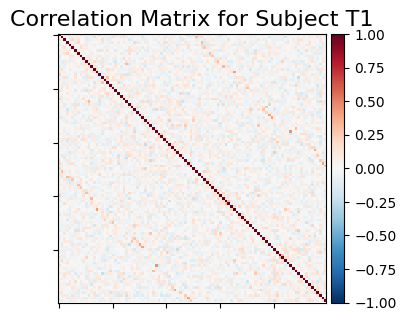

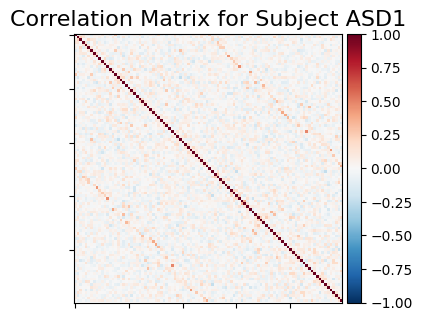

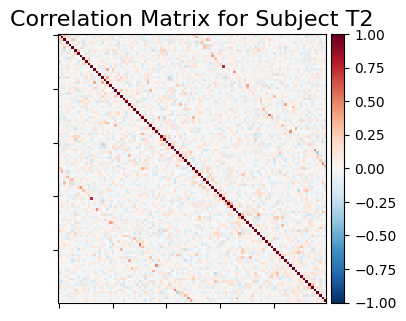

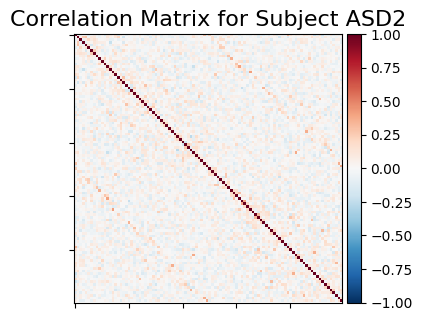

In [ ]:
#Time series shape: (175, 100), Correlation matrix shape: (100, 100)
t1= all_correlation_matrices[0]
asd1= all_correlation_matrices[1]
t2= all_correlation_matrices[2]
asd2= all_correlation_matrices[3]
plotting.plot_matrix(t1, figure=(3, 3), colorbar=True, vmax=1, vmin=-1, title="Correlation Matrix for Subject T1")
plotting.plot_matrix(asd1, figure=(3, 3), colorbar=True, vmax=1, vmin=-1, title="Correlation Matrix for Subject ASD1")
plotting.plot_matrix(t2, figure=(3, 3), colorbar=True, vmax=1, vmin=-1, title="Correlation Matrix for Subject T2")
plotting.plot_matrix(asd2, figure=(3, 3), colorbar=True, vmax=1, vmin=-1, title="Correlation Matrix for Subject ASD2")
plotting.show() 

In [ ]:
coords = plotting.find_parcellation_cut_coords(labels_img=atlas.maps) #Finding the coordinates of the parcels in the atlas using the find_parcellation_cut_coords function. The labels_img parameter specifies the atlas image to be used for finding the coordinates.
print(f"Coordinates of the parcels: {coords}")
distance_matrix = cdist(coords, coords, metric='euclidean') #Computing the distance matrix between the parcels using the cdist function from scipy.spatial.distance. The coords parameter specifies the coordinates of the parcels, and the metric parameter specifies the distance metric to be used (in this case, Euclidean distance).
print(f"Distance matrix shape: {distance_matrix.shape}") 

Coordinates of the parcels: [[-2.58197970e+01 -3.26243655e+01 -1.74593909e+01]
 [-2.54812881e+01 -7.65918190e+01 -1.35143603e+01]
 [-1.64249471e+01 -6.09577167e+01 -6.73572939e+00]
 [-2.71308176e+01 -9.44905660e+01 -4.74465409e+00]
 [-6.22650602e+00 -9.24626506e+01 -3.03614458e+00]
 [-1.26992864e+01 -6.49643221e+01  5.78797146e+00]
 [-4.70372737e+01 -7.08178914e+01  1.05175719e+01]
 [-2.57454545e+01 -8.80149733e+01  2.04973262e+01]
 [-8.30476190e+00 -8.10645503e+01  2.66645503e+01]
 [-5.31723220e+01 -2.24071856e+01  7.94278110e+00]
 [-3.72030361e+01 -2.11537002e+01  1.55104364e+01]
 [-5.45261228e+01 -1.13253896e+01  1.35838680e+01]
 [-5.46137184e+01 -8.24909747e+00  3.34386282e+01]
 [-3.92759009e+01 -2.31936937e+01  5.89256757e+01]
 [-1.13042712e+01 -2.64588287e+01  6.36715103e+01]
 [-4.66188870e+01 -5.68271501e+01 -1.25168634e+01]
 [-5.74897025e+01 -2.49977117e+01  3.85080092e+01]
 [-2.50340843e+01 -6.80323512e+01  4.81825534e+01]
 [-4.17174312e+01 -3.44403670e+01  4.79926606e+01]
 [-

In [ ]:
matrices = [t1, asd1, t2, asd2] #Creating a list of the correlation matrices for the four subjects.
long_range_graphs = []
long_range_mask = distance_matrix > 75.0 #75mm threshold distance to identify long-range connectivity. 
for i, mat in enumerate(matrices):
    current_mat = mat.copy() #Creating a copy of the current correlation matrix to avoid modifying the original matrix.
    np.fill_diagonal(current_mat, 0) #Filling the diagonal of the current correlation matrix with zeros to ignore self-connections.
    adjacency_matrix = (np.abs(current_mat) > 0.1).astype(int) #Creating an adjacency matrix by thresholding the absolute values of the current correlation matrix. Connections with absolute values greater than the threshold are set to 1, and others are set to 0 because i don't look the direction of the connections. 
    fc_long_range = adjacency_matrix * long_range_mask
    long_range_graphs.append(fc_long_range)
    total_connections = np.sum(adjacency_matrix) / 2  # Dividing by 2 to account for the symmetric nature of the adjacency matrix
    long_range_connections = np.sum(fc_long_range) / 2 
    print(f"Subject {i+1}: Total connections: {total_connections}, Long-range connections: {long_range_connections}")
    print(long_range_graphs[i])
    print(np.unique(long_range_graphs[i], return_counts=True)) 

Subject 1: Total connections: 889.0, Long-range connections: 451.0
[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 1 0 0]
 ...
 [0 0 1 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]
(array([0, 1]), array([9098,  902]))
Subject 2: Total connections: 769.0, Long-range connections: 353.0
[[0 0 0 ... 0 0 0]
 [0 0 0 ... 1 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 1 0 ... 0 1 0]
 [0 0 0 ... 1 0 0]
 [0 0 0 ... 0 0 0]]
(array([0, 1]), array([9294,  706]))
Subject 3: Total connections: 1059.0, Long-range connections: 528.0
[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]
(array([0, 1]), array([8944, 1056]))
Subject 4: Total connections: 879.0, Long-range connections: 424.0
[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]
(array([0, 1]), array([9152,  848]))


In [ ]:
#Graph Theory Analysis: The long-range connectivity graphs are analyzed using graph theory metrics. The degree centrality, clustering coefficient, and average path length are computed for each subject's long-range connectivity graph. These metrics provide insights into the network properties of the brain regions involved in long-range connections.
subjects = ['T1', 'ASD1', 'T2', 'ASD2']
all_centrality_scores = []
all_global_efficiency = []

for i, mat in enumerate(long_range_graphs):
    G = nx.from_numpy_array(mat)
    centrality_scores = nx.degree_centrality(G) #Calculating the degree centrality for each node in the graph G. Degree centrality measures the number of connections a node has relative to the total number of possible connections in the graph.
    global_efficiency = nx.global_efficiency(G) #Calculating the global efficiency for the graph G. Global efficiency measures the ability of the network to transfer information across all pairs of nodes, the average inverse shortest path distance between all pairs of nodes.
    all_centrality_scores.append(centrality_scores)
    all_global_efficiency.append(global_efficiency) 
    sorted_hubs = sorted(centrality_scores.items(), key=lambda item: item[1], reverse=True) 
    for node, score in sorted_hubs[:5]: 
        print(f"Subject {subjects[i]}: Node {node} - Degree Centrality: {score}, Global Efficiency: {global_efficiency}")
        anatomik_isim = atlas.labels[node + 1]
        print(f" > İsim: {anatomik_isim} | Skor: {score:.3f}")

Subject T1: Node 41 - Degree Centrality: 0.20202020202020204, Global Efficiency: 0.4702087542087633
 > İsim: 7Networks_LH_Default_PFC_1 | Skor: 0.202
Subject T1: Node 40 - Degree Centrality: 0.18181818181818182, Global Efficiency: 0.4702087542087633
 > İsim: 7Networks_LH_Default_Par_2 | Skor: 0.182
Subject T1: Node 89 - Degree Centrality: 0.17171717171717174, Global Efficiency: 0.4702087542087633
 > İsim: 7Networks_RH_Default_Par_1 | Skor: 0.172
Subject T1: Node 79 - Degree Centrality: 0.16161616161616163, Global Efficiency: 0.4702087542087633
 > İsim: 7Networks_RH_Limbic_TempPole_1 | Skor: 0.162
Subject T1: Node 38 - Degree Centrality: 0.15151515151515152, Global Efficiency: 0.4702087542087633
 > İsim: 7Networks_LH_Default_Temp_2 | Skor: 0.152
Subject ASD1: Node 18 - Degree Centrality: 0.19191919191919193, Global Efficiency: 0.4385723905724079
 > İsim: 7Networks_LH_DorsAttn_Post_4 | Skor: 0.192
Subject ASD1: Node 31 - Degree Centrality: 0.18181818181818182, Global Efficiency: 0.438572

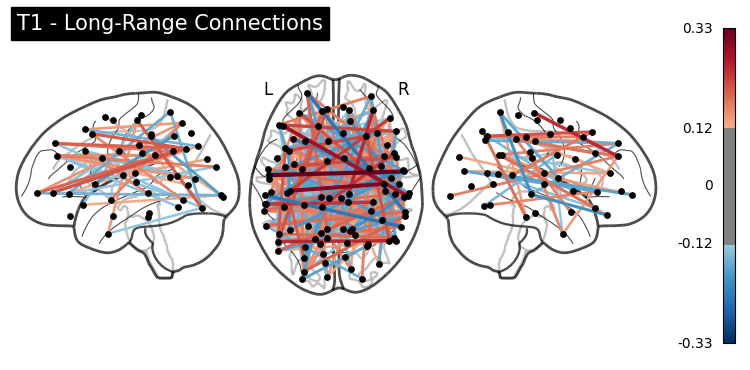

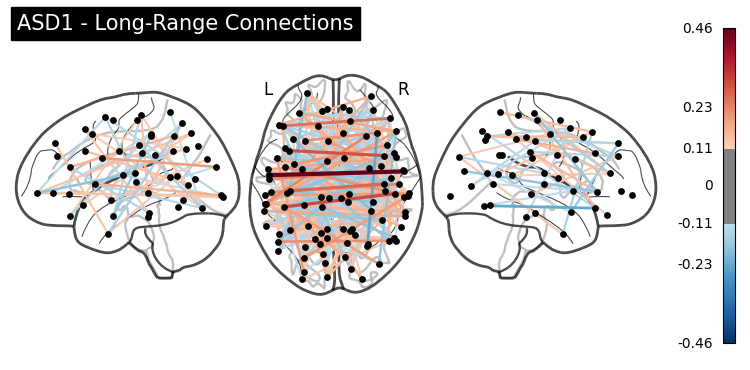

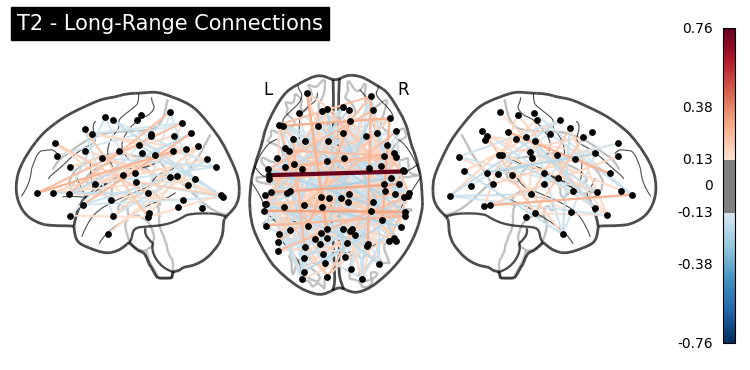

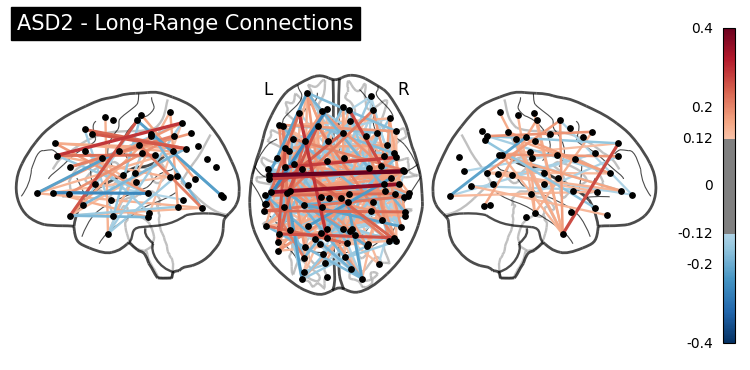

In [ ]:
subjects = ['T1', 'ASD1', 'T2', 'ASD2'] #Creating a list of subject labels for display purposes.

for i, mat in enumerate(matrices):
    continuous_long_range = mat * long_range_mask 
    np.fill_diagonal(continuous_long_range, 0)
    display = plotting.plot_connectome(
        continuous_long_range, 
        coords, 
        title=f"{subjects[i]} - Long-Range Connections",
        node_size=15,          
        edge_threshold='95%',  
        node_color='black',    
        display_mode='lzr',
        colorbar=True)
    plotting.show()

FfMRI files found: 4


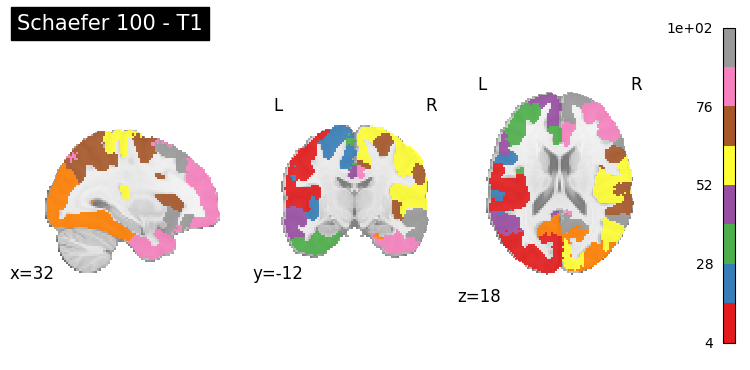

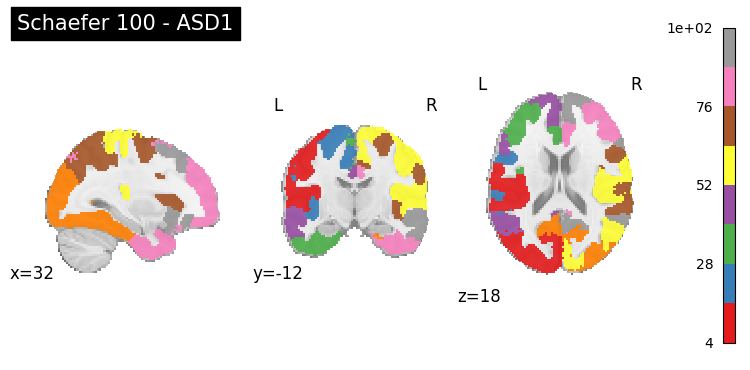

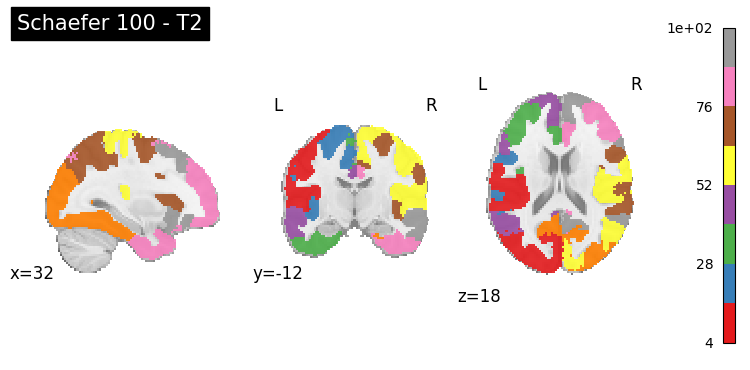

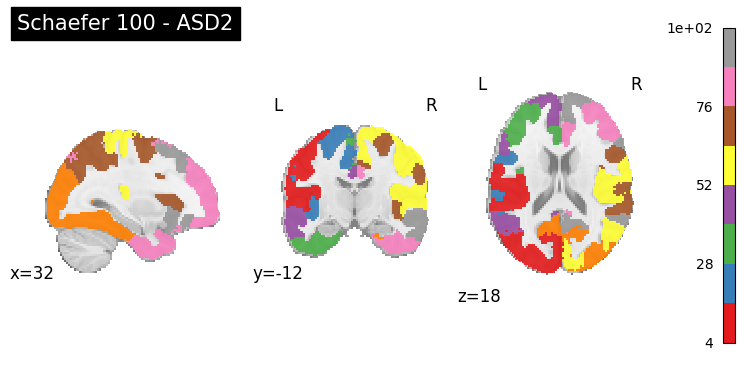

In [ ]:
print(f"FfMRI files found: {len(fmri_files)}")
for i, mat in enumerate(long_range_graphs):
    display = plotting.plot_roi(atlas.maps, display_mode='ortho', title=f"Schaefer 100 - {subjects[i]}", cmap='Set1', alpha=0.9, draw_cross=False)
plotting.show() 

In [ ]:
#Degree Preserving Randomization

num_permutations = 1000

G_observed = nx.from_numpy_array(long_range_graphs[0])  # T1
observed_efficiency = nx.global_efficiency(G_observed)

null_efficiency = []
for _ in range(num_permutations):
    G_rand = G_observed.copy()
    try:
        nx.double_edge_swap(G_rand, 
                             nswap=G_rand.number_of_edges() * 5, 
                             max_tries=G_rand.number_of_edges() * 50)
    except nx.NetworkXError:
        pass
    null_efficiency.append(nx.global_efficiency(G_rand))

null_efficiency = np.array(null_efficiency)
p_value = np.mean(null_efficiency >= observed_efficiency)

print(f"global efficiency: {observed_efficiency:.4f}")
print(f"Null distribution: {null_efficiency.mean():.4f} ± {null_efficiency.std():.4f}")
print(f"Empirical p-value: {p_value:.4f}") 

global efficiency: 0.4702
Null distribution: 0.4700 ± 0.0012
Empirical p-value: 0.4390
